# 🎵 Moosic — Spotify Song Clustering
**5,235 songs · 9 audio features · K-Means k=5 · Silhouette 0.267**

| Step | What |
|------|------|
| 1 | Load & Explore |
| 2 | Scale features |
| 3 | Elbow + Silhouette → choose k |
| 4 | K-Means final model |
| 5 | Mood Compass |
| 6 | PCA + t-SNE |
| 7 | DBSCAN |
| 8 | Agglomerative |
| 9 | Feature Heatmap |
| 10 | Radar Charts |
| 11 | Playlist Signatures |
| 12 | Playlist Profiles + Top Songs |
| 13 | Algorithm Comparison |

## 0 · Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.patches as mpatches, seaborn as sns, math, warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams.update({"figure.dpi":130, "axes.spines.top":False, "axes.spines.right":False})
sns.set_theme(style="whitegrid")

FEATURES = ["danceability","energy","acousticness","tempo",
            "valence","speechiness","instrumentalness","liveness","loudness"]
K = 5
NAMES  = {0:"Hard & Intense", 1:"Energetic Rock", 2:"Pop & Dance",
          3:"Acoustic & Ambient", 4:"Hip-Hop & R&B"}
COLORS = ["#E8644A","#3D9E8C","#7B6BB0","#D4A843","#5A9BB0"]
BLURBS = {
    0:"Maximum intensity — metal and hard rock with relentless energy and dark mood.",
    1:"High-energy rock and alternative — loud, active, and powerful.",
    2:"Mainstream pop and dance — upbeat, danceable, and radio-friendly.",
    3:"Quiet acoustic and ambient pieces — gentle, introspective, mostly instrumental.",
    4:"Rhythm-forward hip-hop and R&B — strong groove and urban attitude.",
}
print("✅ Ready")


✅ Ready


## 1 · Load & Explore

In [2]:
df = pd.read_csv("../spotify_5000_songs.csv")
df.columns = [c.strip() for c in df.columns]
print(f"{len(df):,} tracks · {df['artist'].nunique():,} artists")
df[["name","artist"]+FEATURES[:4]].head()

5,235 tracks · 2,176 artists


,name,artist,danceability,energy,acousticness,tempo
0,Se Eu Quiser Falar Com Deus ...,Gilberto Gil,0.658,0.2590,0.694,110.376
1,Saudade De Bahia ...,Antônio Carlos Jobim,0.742,0.3990,0.217,125.039
2,"Canta Canta, Minha Gente ...",Martinho Da Vila,0.851,0.7300,0.453,93.698
3,Mulher Eu Sei ...,Chico César,0.705,0.0502,0.879,106.802
4,Rosa Morena ...,Kurt Elling,0.651,0.1190,0.916,120.941


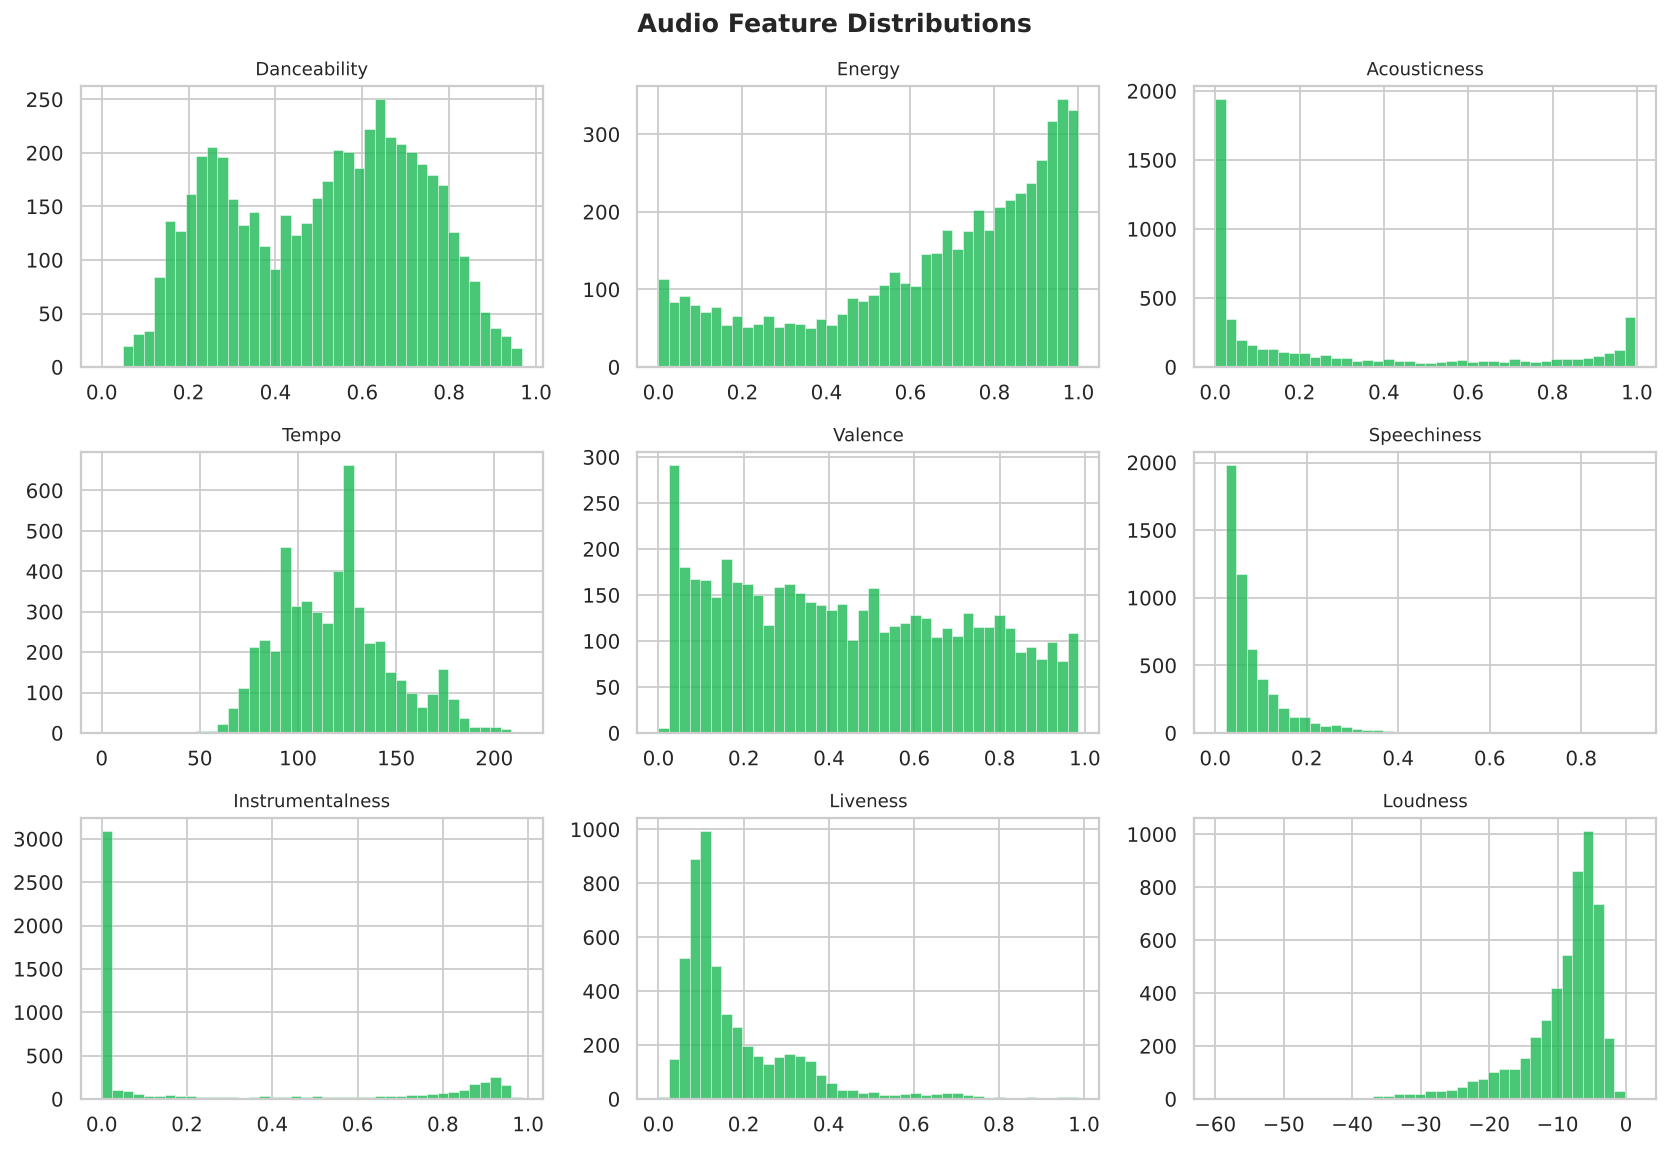

In [3]:
# Distributions + correlation side by side
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
fig.suptitle("Audio Feature Distributions", fontsize=14, fontweight="bold")
for ax, f in zip(axes.flatten(), FEATURES):
    ax.hist(df[f], bins=40, color="#1DB954", edgecolor="white", alpha=0.8, linewidth=0.3)
    ax.set_title(f.title(), fontsize=10)
plt.tight_layout(); plt.show()

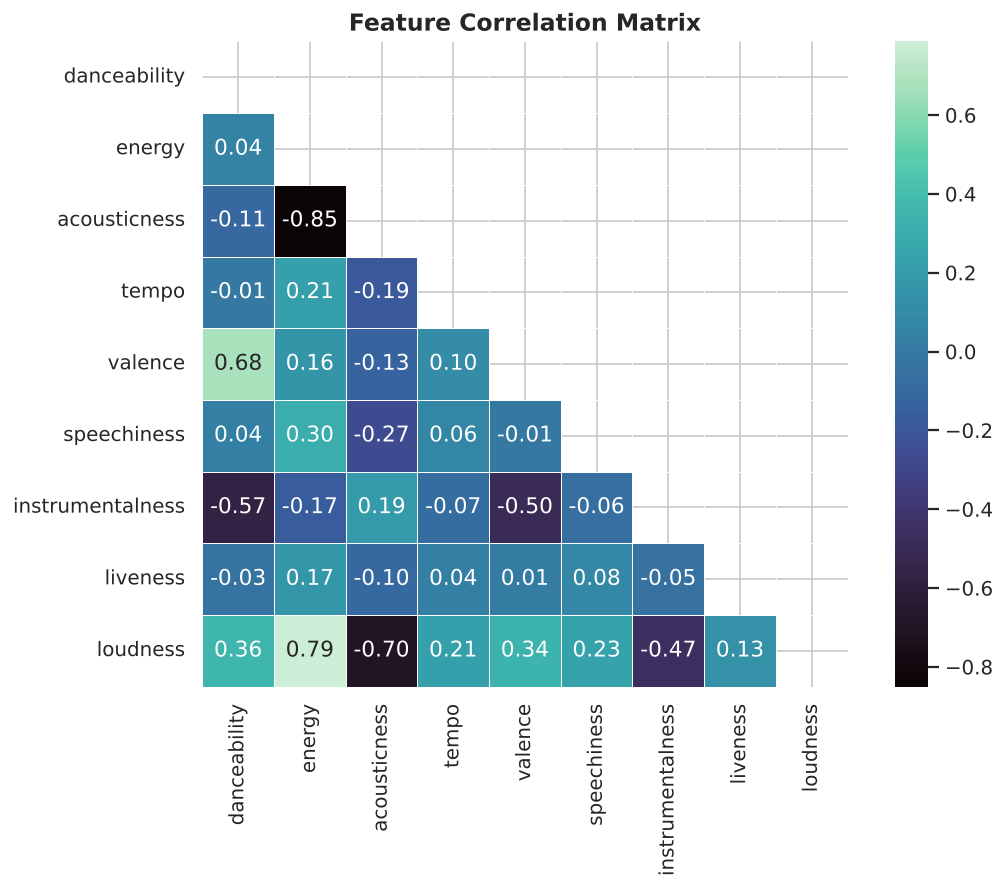

In [4]:
fig, ax = plt.subplots(figsize=(9,7))
mask = np.triu(np.ones((len(FEATURES),len(FEATURES)), dtype=bool))
sns.heatmap(df[FEATURES].corr(), mask=mask, cmap="mako", center=0,
            annot=True, fmt=".2f", square=True, linewidths=0.4, ax=ax)
ax.set_title("Feature Correlation Matrix", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

## 2 · Preprocessing — StandardScaler
Tempo (0–214 BPM) would dominate danceability (0–1) in distance calculations. StandardScaler fixes this: mean=0, std=1 for every feature.

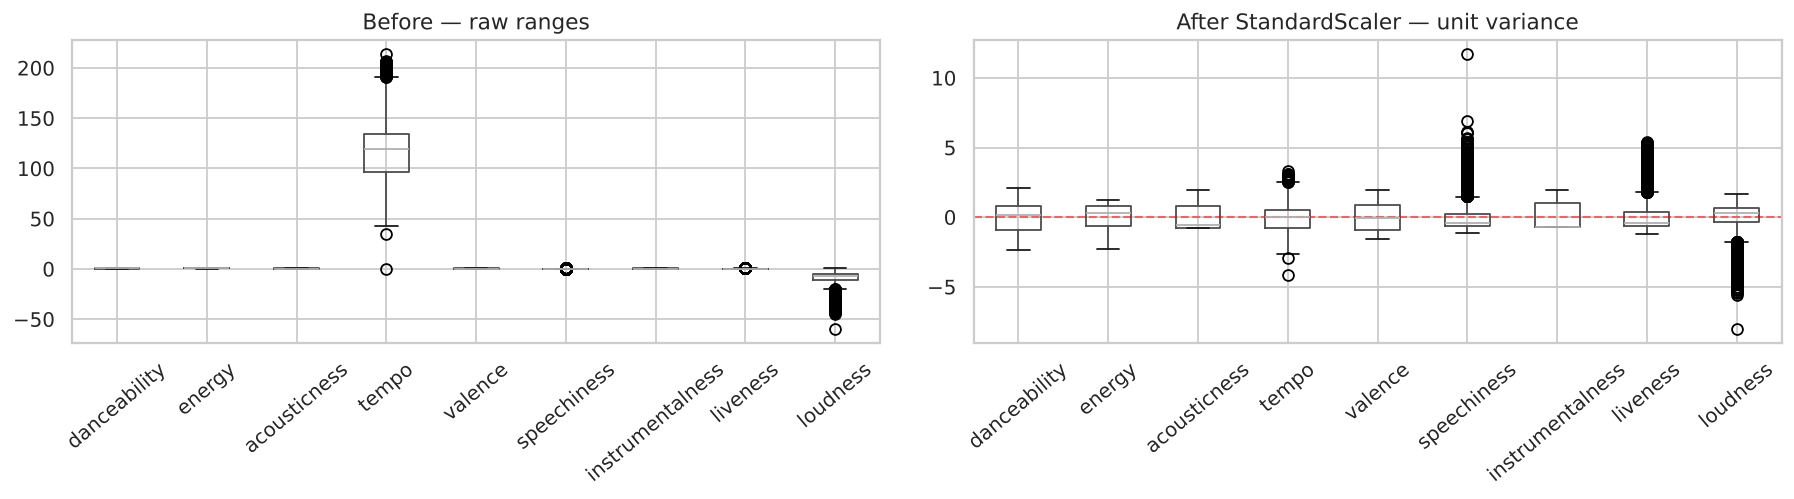

In [5]:
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(df[FEATURES])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14,4))
df[FEATURES].boxplot(ax=a1); a1.set_title("Before — raw ranges"); a1.tick_params(axis="x", rotation=40)
pd.DataFrame(X_scaled, columns=FEATURES).boxplot(ax=a2)
a2.axhline(0, color="red", lw=1.2, ls="--", alpha=0.5)
a2.set_title("After StandardScaler — unit variance"); a2.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

## 3 · Choosing k — Elbow & Silhouette

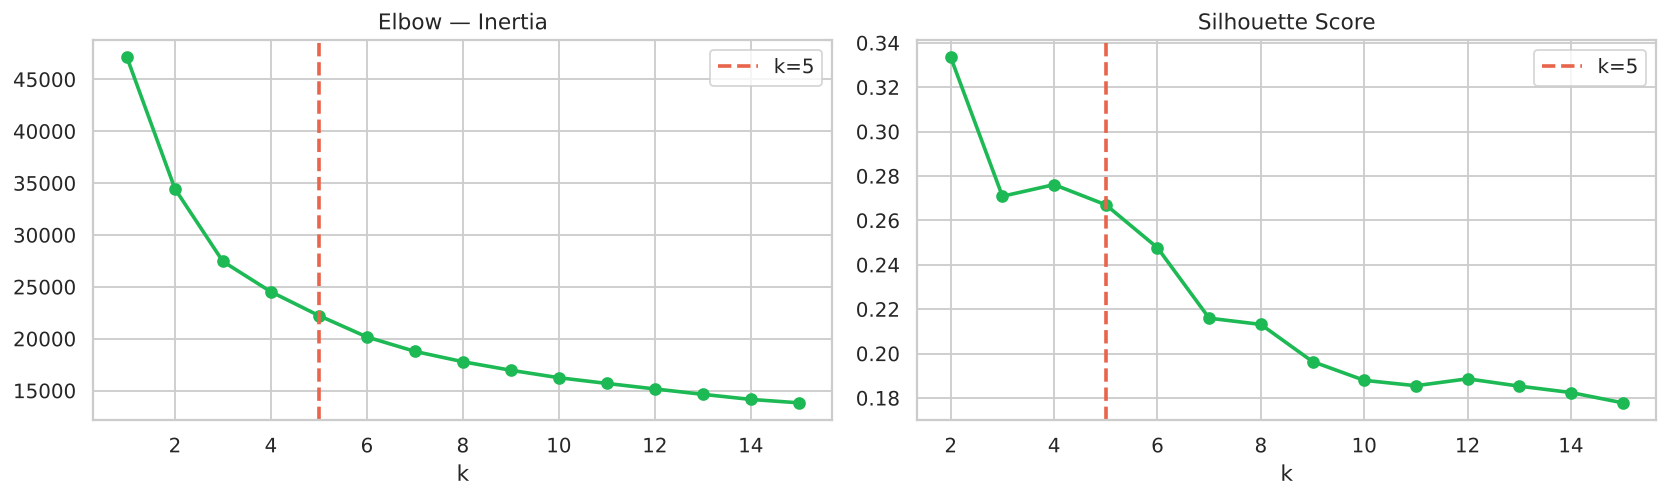

Best silhouette k=2: 0.333 | Chosen k=5: 0.267


In [6]:
inertias, silhouettes = [], []
for k in range(1, 16):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    lbl = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lbl) if k > 1 else None)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13,4))

# Elbow — Inertia
a1.plot(range(1,16), inertias, "o-", color="#1DB954", lw=2)
a1.axvline(K, color="#E8644A", ls="--", lw=2, label=f"k={K}"); a1.legend()
a1.set_title("Elbow — Inertia"); a1.set_xlabel("k")

# Silhouette — line with dots
sil_vals = [s for s in silhouettes if s is not None]
a2.plot(range(2,16), sil_vals, "o-", color="#1DB954", lw=2)
a2.axvline(K, color="#E8644A", ls="--", lw=2, label=f"k={K}"); a2.legend()
a2.set_title("Silhouette Score"); a2.set_xlabel("k")

plt.tight_layout(); plt.show()
print(f"Best silhouette k=2: {max(sil_vals):.3f} | Chosen k=5: {sil_vals[3]:.3f}")


## 4 · Final K-Means Model  (k = 5)

In [7]:
km = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)
df["cluster"] = labels
df["playlist"] = df["cluster"].map(NAMES)

sil = silhouette_score(X_scaled, labels)
counts = pd.Series(labels).value_counts().sort_index()
print(f"Silhouette: {sil:.4f}")
for i in range(K): print(f"  {NAMES[i]}: {counts[i]:,} songs")


Silhouette: 0.2670
  Hard & Intense: 1,210 songs
  Energetic Rock: 553 songs
  Pop & Dance: 2,246 songs
  Acoustic & Ambient: 856 songs
  Hip-Hop & R&B: 370 songs


## 5 · Mood Compass — Valence × Energy
The simplest view any non-technical listener can read. Valence = happiness; Energy = intensity.

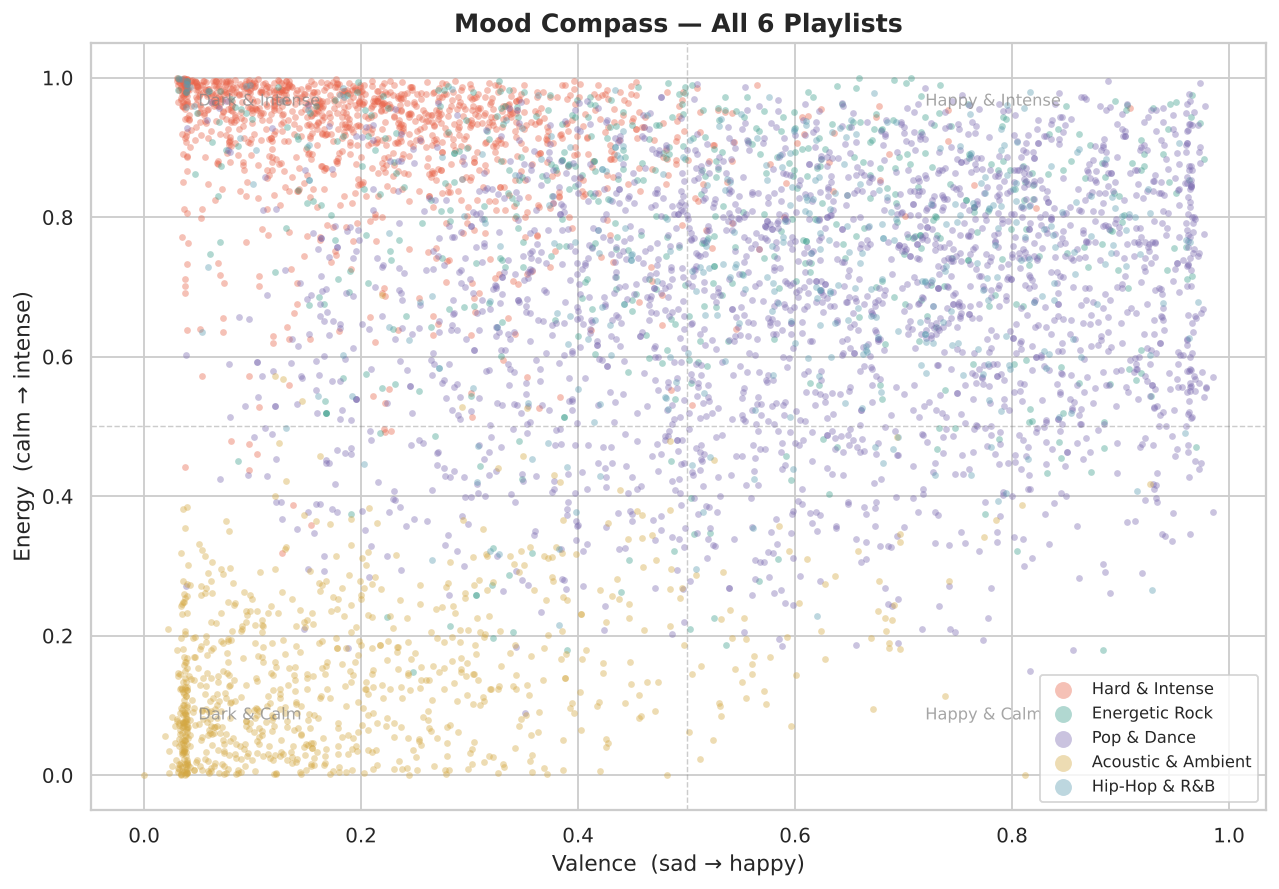

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))
for i in range(K):
    m = labels == i
    ax.scatter(df.loc[m,"valence"], df.loc[m,"energy"],
               c=COLORS[i], label=NAMES[i], alpha=0.4, s=14, linewidths=0)

# Quadrant labels
for txt, xy in [("Dark & Calm","(0.05,0.08)"), ("Dark & Intense","(0.05,0.96)"),
                ("Happy & Calm","(0.72,0.08)"), ("Happy & Intense","(0.72,0.96)")]:
    ax.text(*eval(xy), txt, fontsize=9, color="grey", alpha=0.7)

ax.axhline(0.5, color="grey", lw=0.8, alpha=0.4, ls="--")
ax.axvline(0.5, color="grey", lw=0.8, alpha=0.4, ls="--")
ax.set_xlabel("Valence  (sad → happy)", fontsize=12)
ax.set_ylabel("Energy  (calm → intense)", fontsize=12)
ax.set_title("Mood Compass — All 6 Playlists", fontsize=14, fontweight="bold")
ax.legend(fontsize=9, markerscale=2.5, framealpha=0.8)
plt.tight_layout(); plt.show()

## 6 · PCA + t-SNE — Visualising 9D in 2D

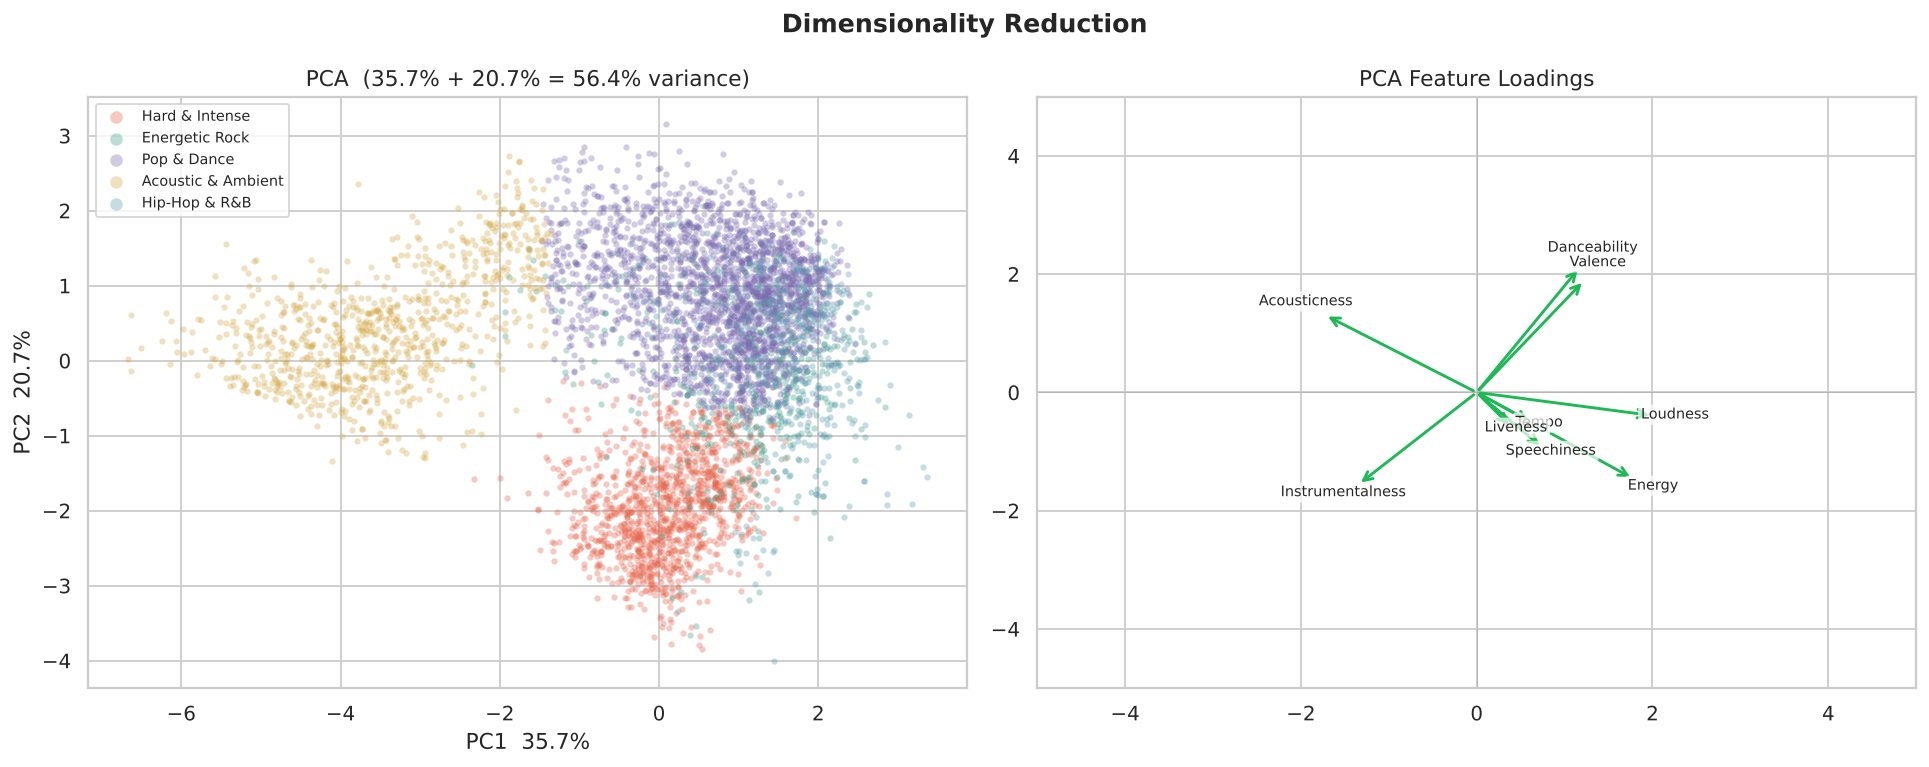

In [9]:
pca = PCA(n_components=2, random_state=42)
Xp  = pca.fit_transform(X_scaled)
v1, v2 = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Dimensionality Reduction", fontsize=14, fontweight="bold")

# PCA scatter
for i in range(K):
    m = labels == i
    axes[0].scatter(Xp[m,0], Xp[m,1], c=COLORS[i], label=NAMES[i], alpha=0.35, s=12, linewidths=0)
axes[0].set_title(f"PCA  ({v1:.1f}% + {v2:.1f}% = {v1+v2:.1f}% variance)")
axes[0].set_xlabel(f"PC1  {v1:.1f}%"); axes[0].set_ylabel(f"PC2  {v2:.1f}%")
axes[0].legend(fontsize=8, markerscale=2)

# Feature loadings
L = pca.components_.T
for i, f in enumerate(FEATURES):
    axes[1].annotate("", xy=(L[i,0]*4,L[i,1]*4), xytext=(0,0),
                     arrowprops=dict(arrowstyle="->", color="#1DB954", lw=1.6))
    axes[1].text(L[i,0]*4.5, L[i,1]*4.5, f.title(), fontsize=8, ha="center",
                 bbox=dict(fc="white", alpha=0.7, ec="none", boxstyle="round,pad=0.2"))
axes[1].set_xlim(-5,5); axes[1].set_ylim(-5,5)
axes[1].axhline(0,color="grey",lw=0.6,alpha=0.3); axes[1].axvline(0,color="grey",lw=0.6,alpha=0.3)
axes[1].set_title("PCA Feature Loadings")
plt.tight_layout(); plt.show()

### 3D PCA — Interactive Cluster View
PCA with `n_components=3` captures three principal axes of variance. Plotly renders it instantly (no waiting) — rotate, zoom, hover to see song & artist. Feature loading arrows show which audio features drive each axis.

In [ ]:
import plotly.graph_objects as go

pca3 = PCA(n_components=3, random_state=42)
Xp3  = pca3.fit_transform(X_scaled)
v1, v2, v3 = pca3.explained_variance_ratio_ * 100

fig_pca3d = go.Figure()
for i in range(K):
    m = labels == i
    fig_pca3d.add_trace(go.Scatter3d(
        x=Xp3[m, 0], y=Xp3[m, 1], z=Xp3[m, 2],
        mode="markers",
        name=NAMES[i],
        text=[f"{row['name']}<br>{row['artist']}" for _, row in df[m].iterrows()],
        hovertemplate="%{text}<extra>" + NAMES[i] + "</extra>",
        marker=dict(size=3, color=COLORS[i], opacity=0.65)
    ))

# Feature loading arrows
L3 = pca3.components_.T * 3
for j, feat in enumerate(FEATURES):
    fig_pca3d.add_trace(go.Scatter3d(
        x=[0, L3[j,0]], y=[0, L3[j,1]], z=[0, L3[j,2]],
        mode="lines+text",
        line=dict(color="#1DB954", width=4),
        text=["", feat.title()],
        textposition="top center",
        textfont=dict(size=10, color="#1DB954"),
        showlegend=False,
        hoverinfo="skip"
    ))

fig_pca3d.update_layout(
    title=dict(
        text=f"3D PCA — {len(X_scaled):,} Songs · {v1:.1f}% + {v2:.1f}% + {v3:.1f}% = {v1+v2+v3:.1f}% variance<br>"
             "<sup>Rotate · Zoom · Hover to see song & artist · Green arrows = feature loadings</sup>",
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(title=f"PC1  {v1:.1f}%", showticklabels=False),
        yaxis=dict(title=f"PC2  {v2:.1f}%", showticklabels=False),
        zaxis=dict(title=f"PC3  {v3:.1f}%", showticklabels=False),
        bgcolor="rgb(245, 240, 232)"
    ),
    legend=dict(title="Playlist", font=dict(size=11)),
    height=750,
    paper_bgcolor="white"
)
fig_pca3d.show()
print(f"✅ 3D PCA — {v1+v2+v3:.1f}% variance explained in 3 components")

In [ ]:
print(f"Running t-SNE on all {len(X_scaled):,} songs … (this takes ~1–2 min)")
Xt2 = TSNE(n_components=2, perplexity=40, n_iter=1000, random_state=42).fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(12, 9))
for i in range(K):
    m = labels == i
    ax.scatter(Xt2[m, 0], Xt2[m, 1], c=COLORS[i], label=NAMES[i],
               alpha=0.45, s=14, linewidths=0)
ax.set_title(f"t-SNE  (all {len(X_scaled):,} songs · perplexity=40)",
             fontsize=13, fontweight="bold")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(fontsize=9, markerscale=2)
plt.tight_layout(); plt.show()
print("✅ 2D t-SNE done")

### 3D t-SNE — Interactive Cluster View
Running t-SNE with `n_components=3` gives each song an X, Y, Z coordinate.
Plotly renders this as an interactive 3D scatter — rotate, zoom, and hover to see song names.

In [ ]:
# Install plotly if not already installed
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "plotly", "--quiet"])
print("✅ plotly ready")

In [ ]:
import plotly.graph_objects as go

print(f"Running 3D t-SNE on all {len(X_scaled):,} songs … (this takes ~2–3 min)")
Xt3 = TSNE(n_components=3, perplexity=40, n_iter=1000, random_state=42).fit_transform(X_scaled)
print("✅ 3D t-SNE done — building interactive plot …")

fig3d = go.Figure()
for i in range(K):
    m = labels == i
    fig3d.add_trace(go.Scatter3d(
        x=Xt3[m, 0], y=Xt3[m, 1], z=Xt3[m, 2],
        mode="markers",
        name=NAMES[i],
        text=[f"{row['name']}<br>{row['artist']}" for _, row in df[m].iterrows()],
        hovertemplate="%{text}<extra>" + NAMES[i] + "</extra>",
        marker=dict(size=3, color=COLORS[i], opacity=0.7)
    ))

fig3d.update_layout(
    title=dict(
        text=f"3D t-SNE — {len(X_scaled):,} Songs · 5 Clusters<br>"
             "<sup>Rotate · Zoom · Hover over any dot to see song & artist</sup>",
        font=dict(size=16)
    ),
    scene=dict(
        xaxis=dict(title="t-SNE 1", showticklabels=False),
        yaxis=dict(title="t-SNE 2", showticklabels=False),
        zaxis=dict(title="t-SNE 3", showticklabels=False),
        bgcolor="rgb(245, 240, 232)"
    ),
    legend=dict(title="Playlist", font=dict(size=11)),
    height=750,
    paper_bgcolor="white"
)

fig3d.show()
print("✅ 3D t-SNE interactive plot rendered")

### 3D UMAP — Modern Dimensionality Reduction
UMAP (Uniform Manifold Approximation and Projection) is faster than t-SNE and better preserves **global structure** — clusters stay in their true relative positions in 3D space. This is the state-of-the-art technique for high-dimensional data visualization.

In [ ]:
# Install umap-learn if needed
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "umap-learn", "--quiet"])
print("✅ umap-learn ready")

In [ ]:
import plotly.graph_objects as go
import umap

print(f"Running 3D UMAP on all {len(X_scaled):,} songs … (this takes ~30–60 sec)")
reducer = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=42, n_jobs=1)
Xu3 = reducer.fit_transform(X_scaled)
print("✅ 3D UMAP done — building interactive plot …")

fig_umap3d = go.Figure()
for i in range(K):
    m = labels == i
    fig_umap3d.add_trace(go.Scatter3d(
        x=Xu3[m, 0], y=Xu3[m, 1], z=Xu3[m, 2],
        mode="markers",
        name=NAMES[i],
        text=[f"{row['name']}<br>{row['artist']}" for _, row in df[m].iterrows()],
        hovertemplate="%{text}<extra>" + NAMES[i] + "</extra>",
        marker=dict(size=3, color=COLORS[i], opacity=0.75)
    ))

fig_umap3d.update_layout(
    title=dict(
        text=f"3D UMAP — {len(X_scaled):,} Songs · 5 Clusters<br>"
             "<sup>Rotate · Zoom · Hover to see song & artist · Preserves global cluster structure better than t-SNE</sup>",
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(title="UMAP 1", showticklabels=False),
        yaxis=dict(title="UMAP 2", showticklabels=False),
        zaxis=dict(title="UMAP 3", showticklabels=False),
        bgcolor="rgb(245, 240, 232)"
    ),
    legend=dict(title="Playlist", font=dict(size=11)),
    height=750,
    paper_bgcolor="white"
)
fig_umap3d.show()
print("✅ 3D UMAP interactive plot rendered")

### 3D Centroid Distance Map
Shows just the 5 cluster centroids in 3D PCA space. Sphere size = number of songs. Lines connect every pair of clusters — their length shows how **musically distant** each playlist is from the others.

In [ ]:
from itertools import combinations

# Project centroids into 3D PCA space
centroids_3d = pca3.transform(km.cluster_centers_)
counts_k = pd.Series(labels).value_counts().sort_index()

fig_cent = go.Figure()

# Lines between all centroid pairs
for i, j in combinations(range(K), 2):
    dist = np.linalg.norm(centroids_3d[i] - centroids_3d[j])
    fig_cent.add_trace(go.Scatter3d(
        x=[centroids_3d[i,0], centroids_3d[j,0]],
        y=[centroids_3d[i,1], centroids_3d[j,1]],
        z=[centroids_3d[i,2], centroids_3d[j,2]],
        mode="lines",
        line=dict(color="#ccbbaa", width=2),
        hovertemplate=f"{NAMES[i]} ↔ {NAMES[j]}<br>Distance: {dist:.2f}<extra></extra>",
        showlegend=False
    ))

# Centroid spheres
fig_cent.add_trace(go.Scatter3d(
    x=centroids_3d[:, 0], y=centroids_3d[:, 1], z=centroids_3d[:, 2],
    mode="markers+text",
    text=[f"{NAMES[i]}<br>{counts_k[i]:,} songs" for i in range(K)],
    textposition="top center",
    textfont=dict(size=11),
    hovertemplate="%{text}<extra></extra>",
    marker=dict(
        size=[counts_k[i] / 60 for i in range(K)],
        color=COLORS,
        opacity=0.9,
        line=dict(color="white", width=1)
    ),
    showlegend=False
))

fig_cent.update_layout(
    title=dict(
        text="3D Centroid Distance Map — How Far Apart Are the Playlists?<br>"
             "<sup>Sphere size = number of songs · Line length = musical distance between clusters</sup>",
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(title=f"PC1  {v1:.1f}%", showticklabels=False),
        yaxis=dict(title=f"PC2  {v2:.1f}%", showticklabels=False),
        zaxis=dict(title=f"PC3  {v3:.1f}%", showticklabels=False),
        bgcolor="rgb(245, 240, 232)"
    ),
    height=700,
    paper_bgcolor="white"
)
fig_cent.show()

# Print distance matrix
print("Pairwise centroid distances (original 9D space):\n")
print(f"{'':22}", end="")
for i in range(K): print(f"{NAMES[i][:12]:>14}", end="")
print()
for i in range(K):
    print(f"{NAMES[i][:22]:22}", end="")
    for j in range(K):
        d = np.linalg.norm(km.cluster_centers_[i] - km.cluster_centers_[j])
        print(f"{'—':>14}" if i==j else f"{d:>14.2f}", end="")
    print()
print("\n✅ 3D Centroid Distance Map done")

### 3D Feature Space Explorer
Pick any **3 audio features** as the X, Y, Z axes using the dropdown menus. See all 5,000 songs plotted in that raw feature space — great for exploring relationships like Energy × Danceability × Valence.

In [ ]:
import plotly.graph_objects as go
from itertools import permutations

# Default axes
fx, fy, fz = "energy", "danceability", "valence"

def make_explorer(fx, fy, fz):
    fig = go.Figure()
    for i in range(K):
        m = labels == i
        fig.add_trace(go.Scatter3d(
            x=df.loc[m, fx], y=df.loc[m, fy], z=df.loc[m, fz],
            mode="markers",
            name=NAMES[i],
            text=[f"{row['name']}<br>{row['artist']}" for _, row in df[m].iterrows()],
            hovertemplate="%{text}<extra>" + NAMES[i] + "</extra>",
            marker=dict(size=3, color=COLORS[i], opacity=0.65)
        ))

    # Build dropdown buttons for all axis combinations
    btn_x = [dict(
        args=[{"x": [df.loc[labels==i, f].values for i in range(K)]}],
        label=f"X: {f.title()}", method="restyle"
    ) for f in FEATURES]
    btn_y = [dict(
        args=[{"y": [df.loc[labels==i, f].values for i in range(K)]}],
        label=f"Y: {f.title()}", method="restyle"
    ) for f in FEATURES]
    btn_z = [dict(
        args=[{"z": [df.loc[labels==i, f].values for i in range(K)]}],
        label=f"Z: {f.title()}", method="restyle"
    ) for f in FEATURES]

    fig.update_layout(
        title=dict(
            text=f"3D Feature Space Explorer — {len(df):,} Songs<br>"
                 f"<sup>Currently: X={fx.title()} · Y={fy.title()} · Z={fz.title()} · Use dropdowns to change axes</sup>",
            font=dict(size=15)
        ),
        scene=dict(
            xaxis=dict(title=fx.title()),
            yaxis=dict(title=fy.title()),
            zaxis=dict(title=fz.title()),
            bgcolor="rgb(245, 240, 232)"
        ),
        updatemenus=[
            dict(buttons=btn_x, direction="down", x=0.05, y=1.12, showactive=True,
                 bgcolor="#f5f0e8", bordercolor="#ccbbaa"),
            dict(buttons=btn_y, direction="down", x=0.35, y=1.12, showactive=True,
                 bgcolor="#f5f0e8", bordercolor="#ccbbaa"),
            dict(buttons=btn_z, direction="down", x=0.65, y=1.12, showactive=True,
                 bgcolor="#f5f0e8", bordercolor="#ccbbaa"),
        ],
        legend=dict(title="Playlist", font=dict(size=11)),
        height=780,
        paper_bgcolor="white"
    )
    return fig

fig_explorer = make_explorer(fx, fy, fz)
fig_explorer.show()
print("✅ 3D Feature Space Explorer — use the three dropdowns to change X / Y / Z axes")

## 7 · DBSCAN — Density-Based Alternative
DBSCAN finds clusters by density, without needing k. The k-distance graph reveals the right eps.

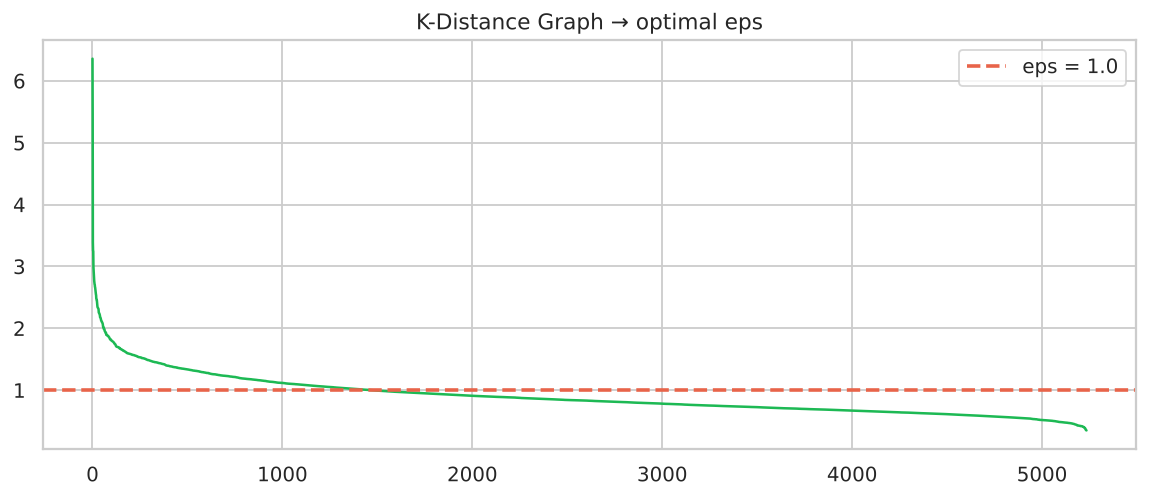

In [11]:
# k-distance graph
dists, _ = NearestNeighbors(n_neighbors=5).fit(X_scaled).kneighbors(X_scaled)
kdist = np.sort(dists[:,4])[::-1]

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(kdist, color="#1DB954", lw=1.4)
ax.axhline(1.0, color="#E8644A", lw=2, ls="--", label="eps = 1.0")
ax.set_title("K-Distance Graph → optimal eps"); ax.legend(); plt.tight_layout(); plt.show()

In [12]:
# eps sweep
print(f"{'eps':>5}  {'clusters':>9}  {'noise%':>7}  {'silhouette':>11}")
for eps in [0.5, 0.8, 1.0, 1.2, 1.5]:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    l  = db.labels_
    nc = len(set(l)) - 1
    nn = np.sum(l==-1)
    non = l[l!=-1]
    s  = silhouette_score(X_scaled[l!=-1], non) if len(set(non))>=2 else float("nan")
    print(f"{eps:>5.1f}  {nc:>9}  {nn/len(l)*100:>6.1f}%  {s:>11.4f}")

print("\n→ High noise fraction confirms Spotify's space is continuous — K-Means wins.")

  eps   clusters   noise%   silhouette
  0.5         30    93.1%       0.1906


  0.8         14    39.0%      -0.2009


  1.0          7    17.8%      -0.0220


  1.2          2     8.6%       0.1093


  1.5          2     2.4%       0.2680

→ High noise fraction confirms Spotify's space is continuous — K-Means wins.


## 8 · Agglomerative Clustering — Hierarchical

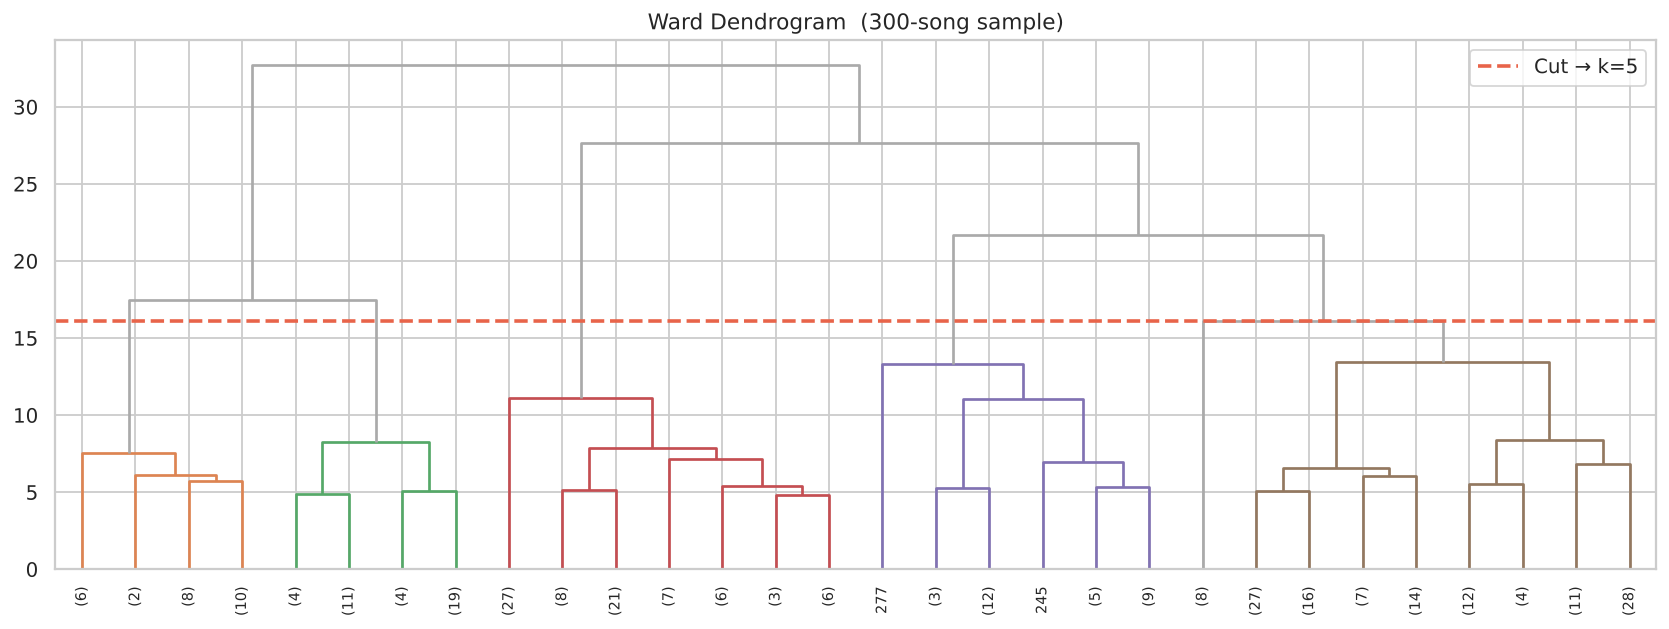

In [13]:
# Dendrogram on 300-song sample
idx2 = np.random.default_rng(42).choice(len(X_scaled), 300, replace=False)
Z    = linkage(X_scaled[idx2], method="ward")

fig, ax = plt.subplots(figsize=(13,5))
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
           color_threshold=Z[-K,2], above_threshold_color="#AAAAAA")
ax.axhline(Z[-K,2], color="#E8644A", lw=2, ls="--", label=f"Cut → k={K}")
ax.set_title("Ward Dendrogram  (300-song sample)"); ax.legend()
plt.tight_layout(); plt.show()

In [14]:
# Linkage comparison
for method in ["ward","complete","average","single"]:
    s = silhouette_score(X_scaled, AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_scaled))
    print(f"  {method:>10}  silhouette = {s:.4f}{'  ← best' if method=='ward' else ''}")

        ward  silhouette = 0.2049  ← best


    complete  silhouette = 0.2219


     average  silhouette = 0.3277


      single  silhouette = 0.3340


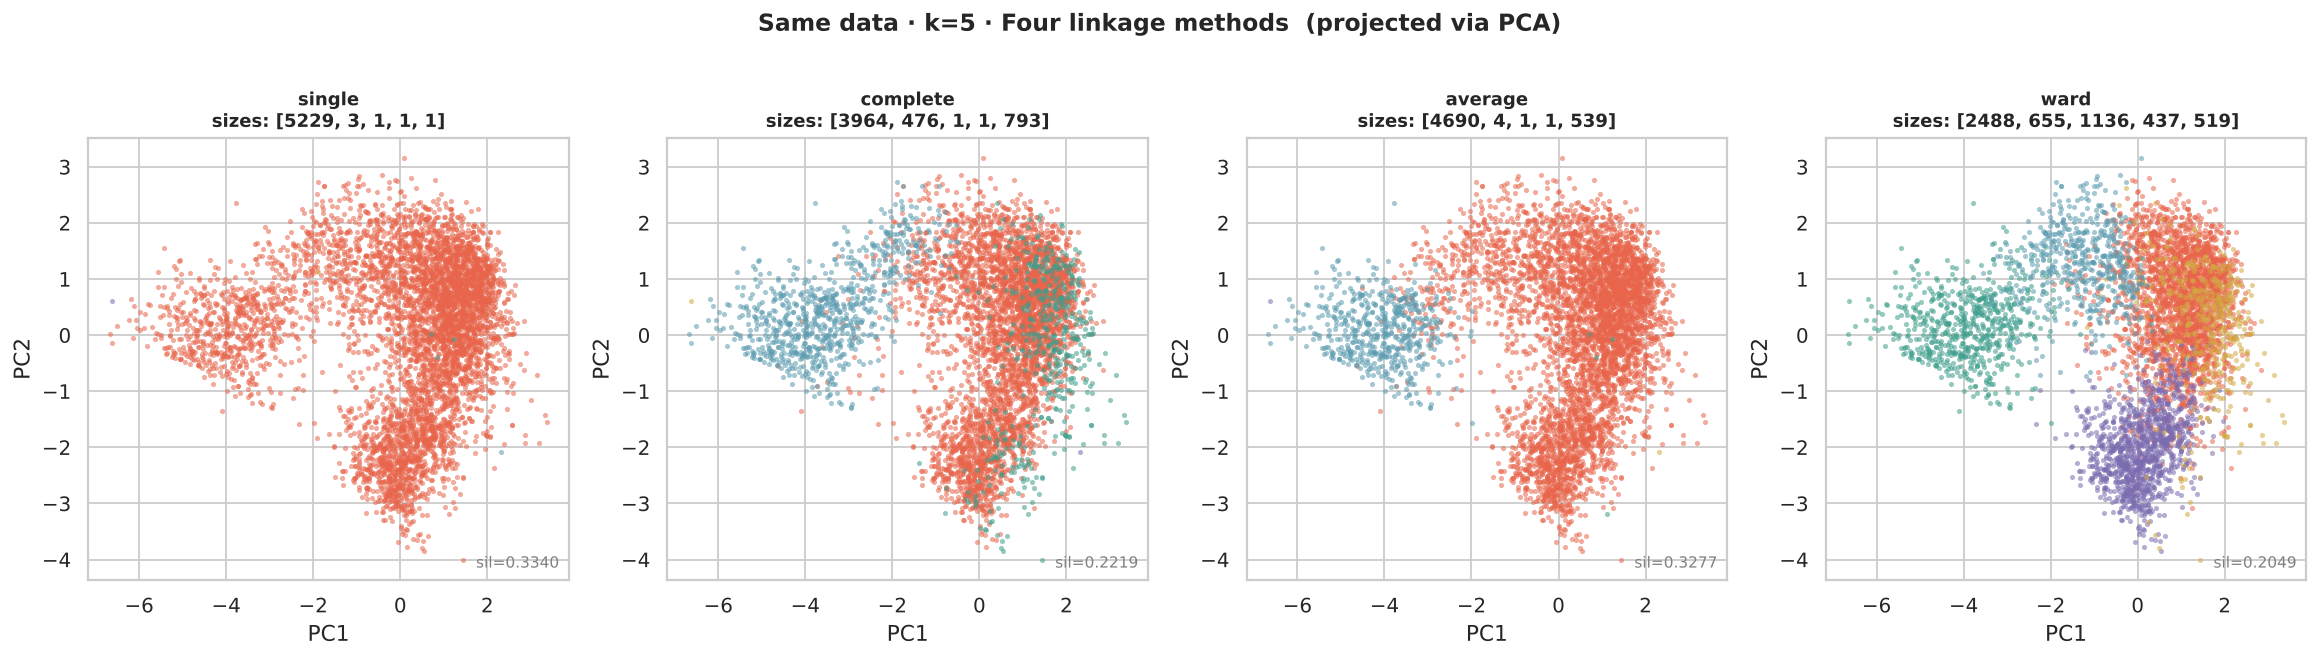

Ward linkage produces the most balanced, well-separated clusters → highest silhouette.


In [15]:
# Linkage comparison — visual (same data, 4 linkage methods, PCA projection)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Same data · k=5 · Four linkage methods  (projected via PCA)",
             fontsize=13, fontweight="bold", y=1.01)

for ax, method in zip(axes, ["single", "complete", "average", "ward"]):
    lbl = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_scaled)
    pca2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
    sizes = [int((lbl==i).sum()) for i in range(K)]
    for ci in range(K):
        m = lbl == ci
        ax.scatter(pca2[m, 0], pca2[m, 1], c=COLORS[ci], s=8, alpha=0.55, linewidths=0)
    ax.set_title(f"{method}\nsizes: {sizes}", fontsize=10, fontweight="bold")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    sil = silhouette_score(X_scaled, lbl)
    ax.text(0.98, 0.02, f"sil={sil:.4f}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8.5, color="grey")

plt.tight_layout(); plt.show()
print("Ward linkage produces the most balanced, well-separated clusters → highest silhouette.")

## 9 · Feature Heatmap — What Each Playlist Sounds Like

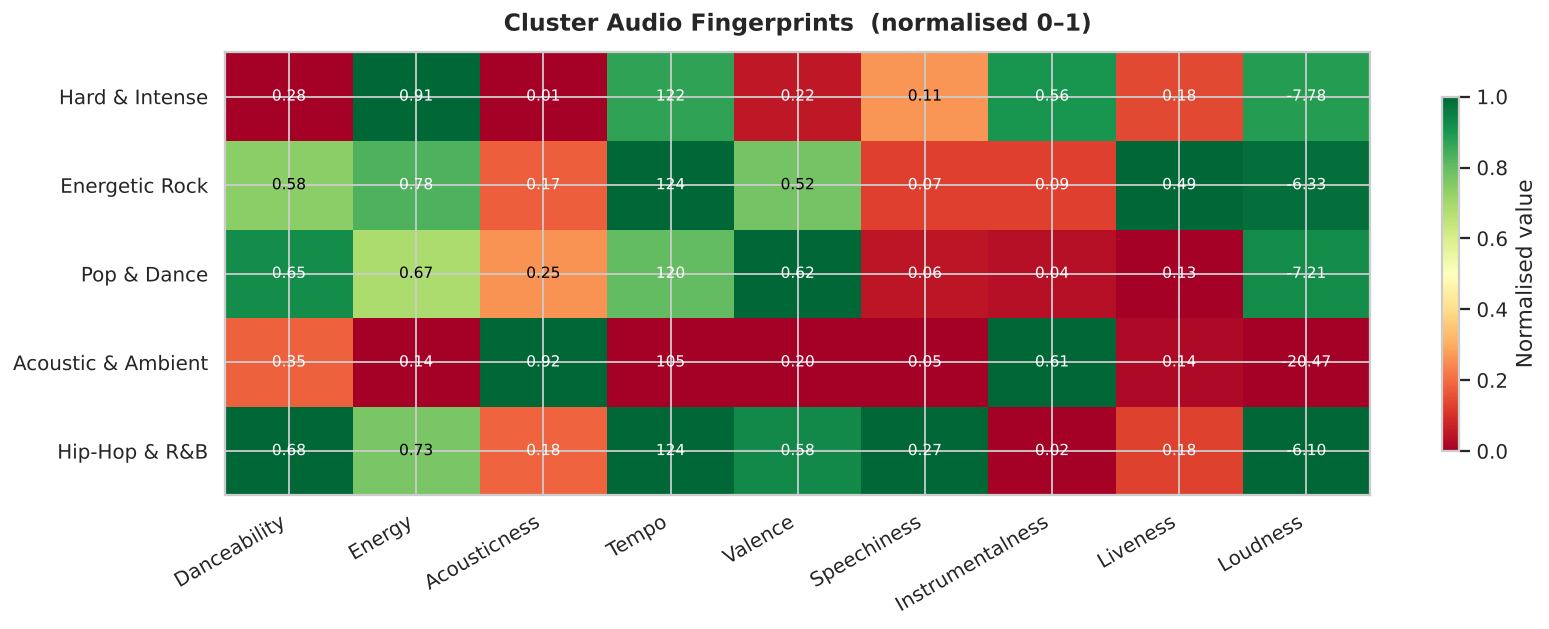

In [16]:
centroids = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_),
                         columns=FEATURES, index=[NAMES[i] for i in range(K)])
hdata = pd.DataFrame(MinMaxScaler().fit_transform(centroids), columns=FEATURES, index=centroids.index)

fig, ax = plt.subplots(figsize=(13,5))
im = ax.imshow(hdata.values, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels([f.title() for f in FEATURES], rotation=30, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(hdata.index)
ax.set_title("Cluster Audio Fingerprints  (normalised 0–1)", fontsize=13, fontweight="bold", pad=12)
for r in range(K):
    for c in range(len(FEATURES)):
        raw = centroids.values[r,c]
        txt = f"{raw:.0f}" if FEATURES[c]=="tempo" else f"{raw:.2f}"
        col = "black" if 0.2 < hdata.values[r,c] < 0.78 else "white"
        ax.text(c, r, txt, ha="center", va="center", fontsize=8.5, color=col)
plt.colorbar(im, ax=ax, label="Normalised value", shrink=0.8)
plt.tight_layout(); plt.show()

## 10 · Radar Charts — Audio Fingerprints per Playlist

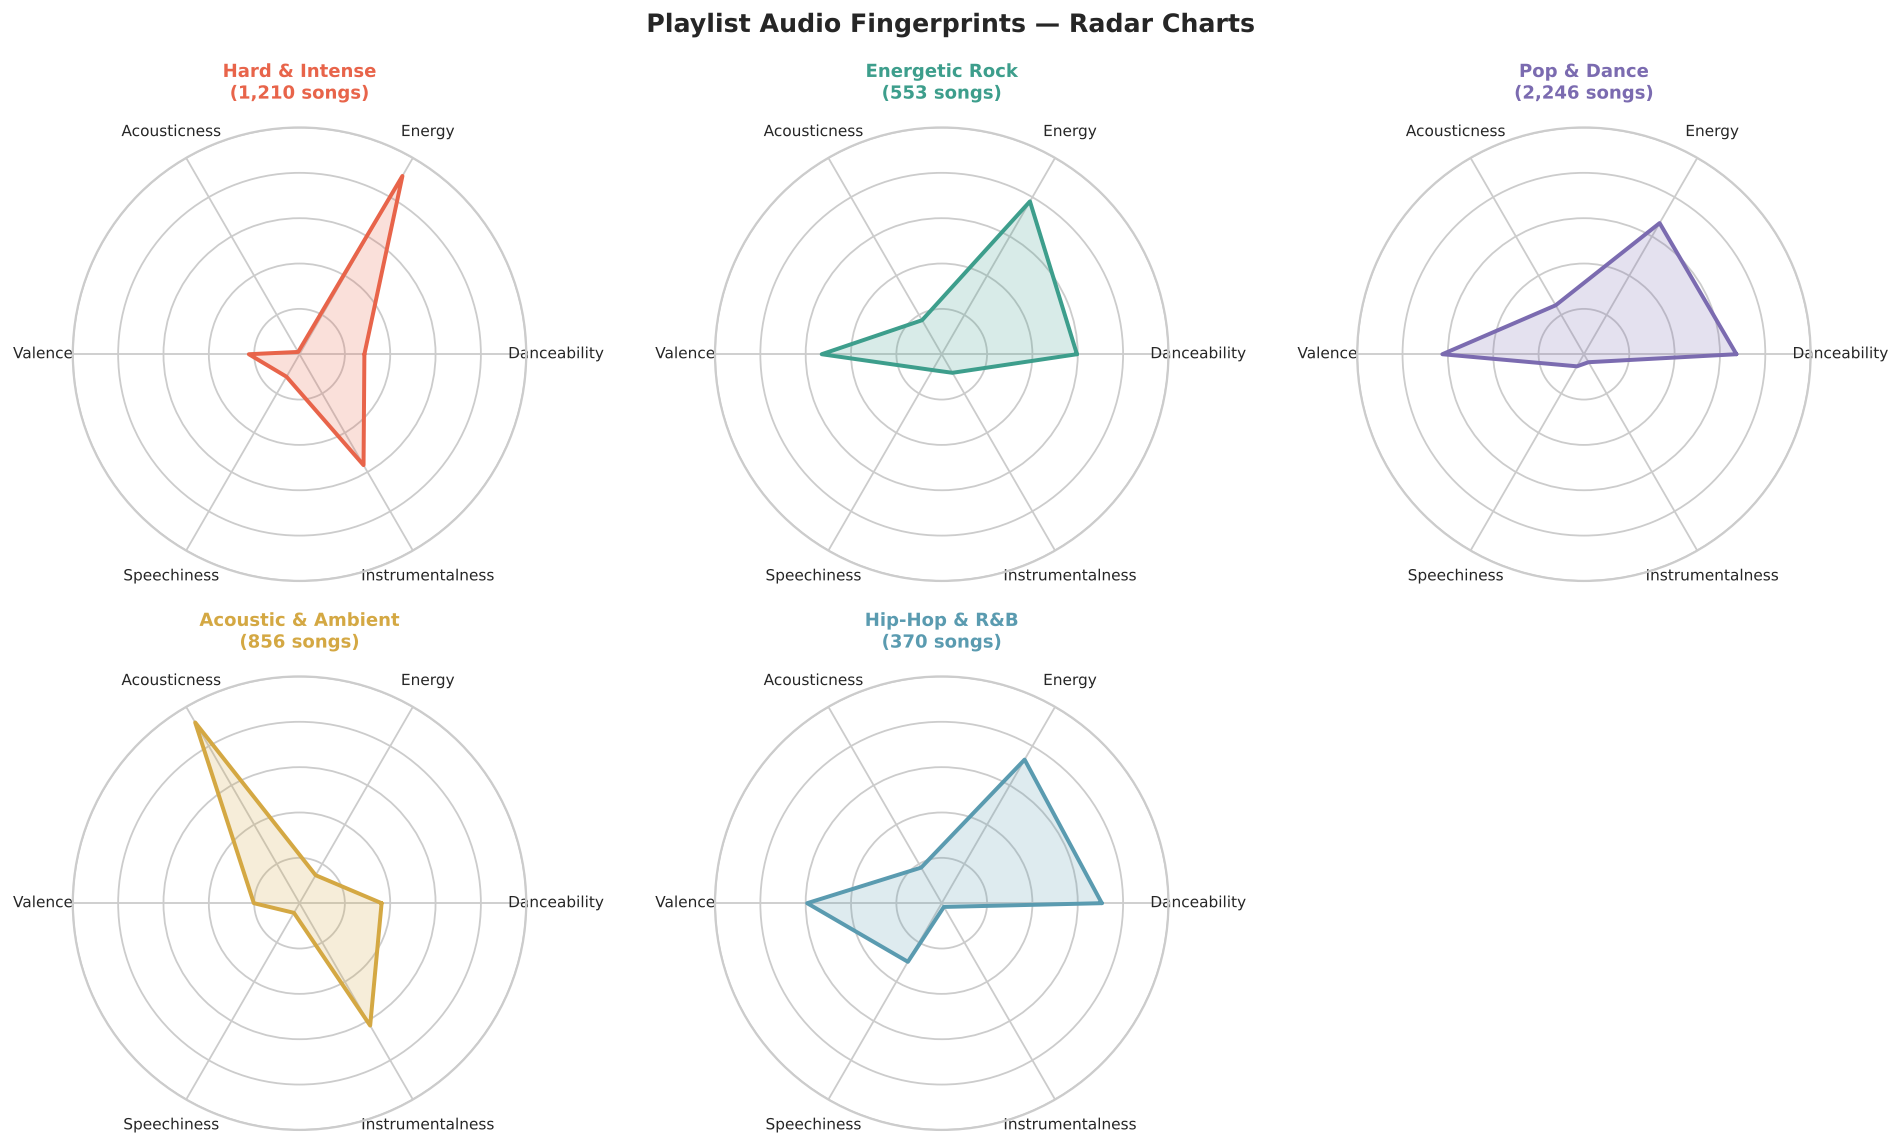

In [17]:
RF = ["danceability","energy","acousticness","valence","speechiness","instrumentalness"]
cr = centroids[RF].copy()
for f in RF:
    cr[f] = (cr[f]-df[f].min())/(df[f].max()-df[f].min())

ang = [n/len(RF)*2*math.pi for n in range(len(RF))]; ang += ang[:1]

fig, axes = plt.subplots(2, 3, figsize=(15,9), subplot_kw=dict(polar=True))
fig.suptitle("Playlist Audio Fingerprints — Radar Charts", fontsize=14, fontweight="bold")
for i, ax in enumerate(axes.flatten()):
    if i >= K: ax.axis('off'); continue
    vals = cr.iloc[i].tolist(); v = vals + [vals[0]]
    ax.plot(ang, v, color=COLORS[i], lw=2.2)
    ax.fill(ang, v, color=COLORS[i], alpha=0.20)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels([f.title() for f in RF], size=8.5)
    ax.set_yticklabels([]); ax.set_ylim(0,1)
    ax.set_title(f"{NAMES[i]}\n({pd.Series(labels).value_counts()[i]:,} songs)",
                 size=10, fontweight="bold", pad=16, color=COLORS[i])
plt.tight_layout(); plt.show()

## 11 · Playlist Signatures
Each chart shows the audio personality of one playlist on all 9 features — the full picture, not just 6.

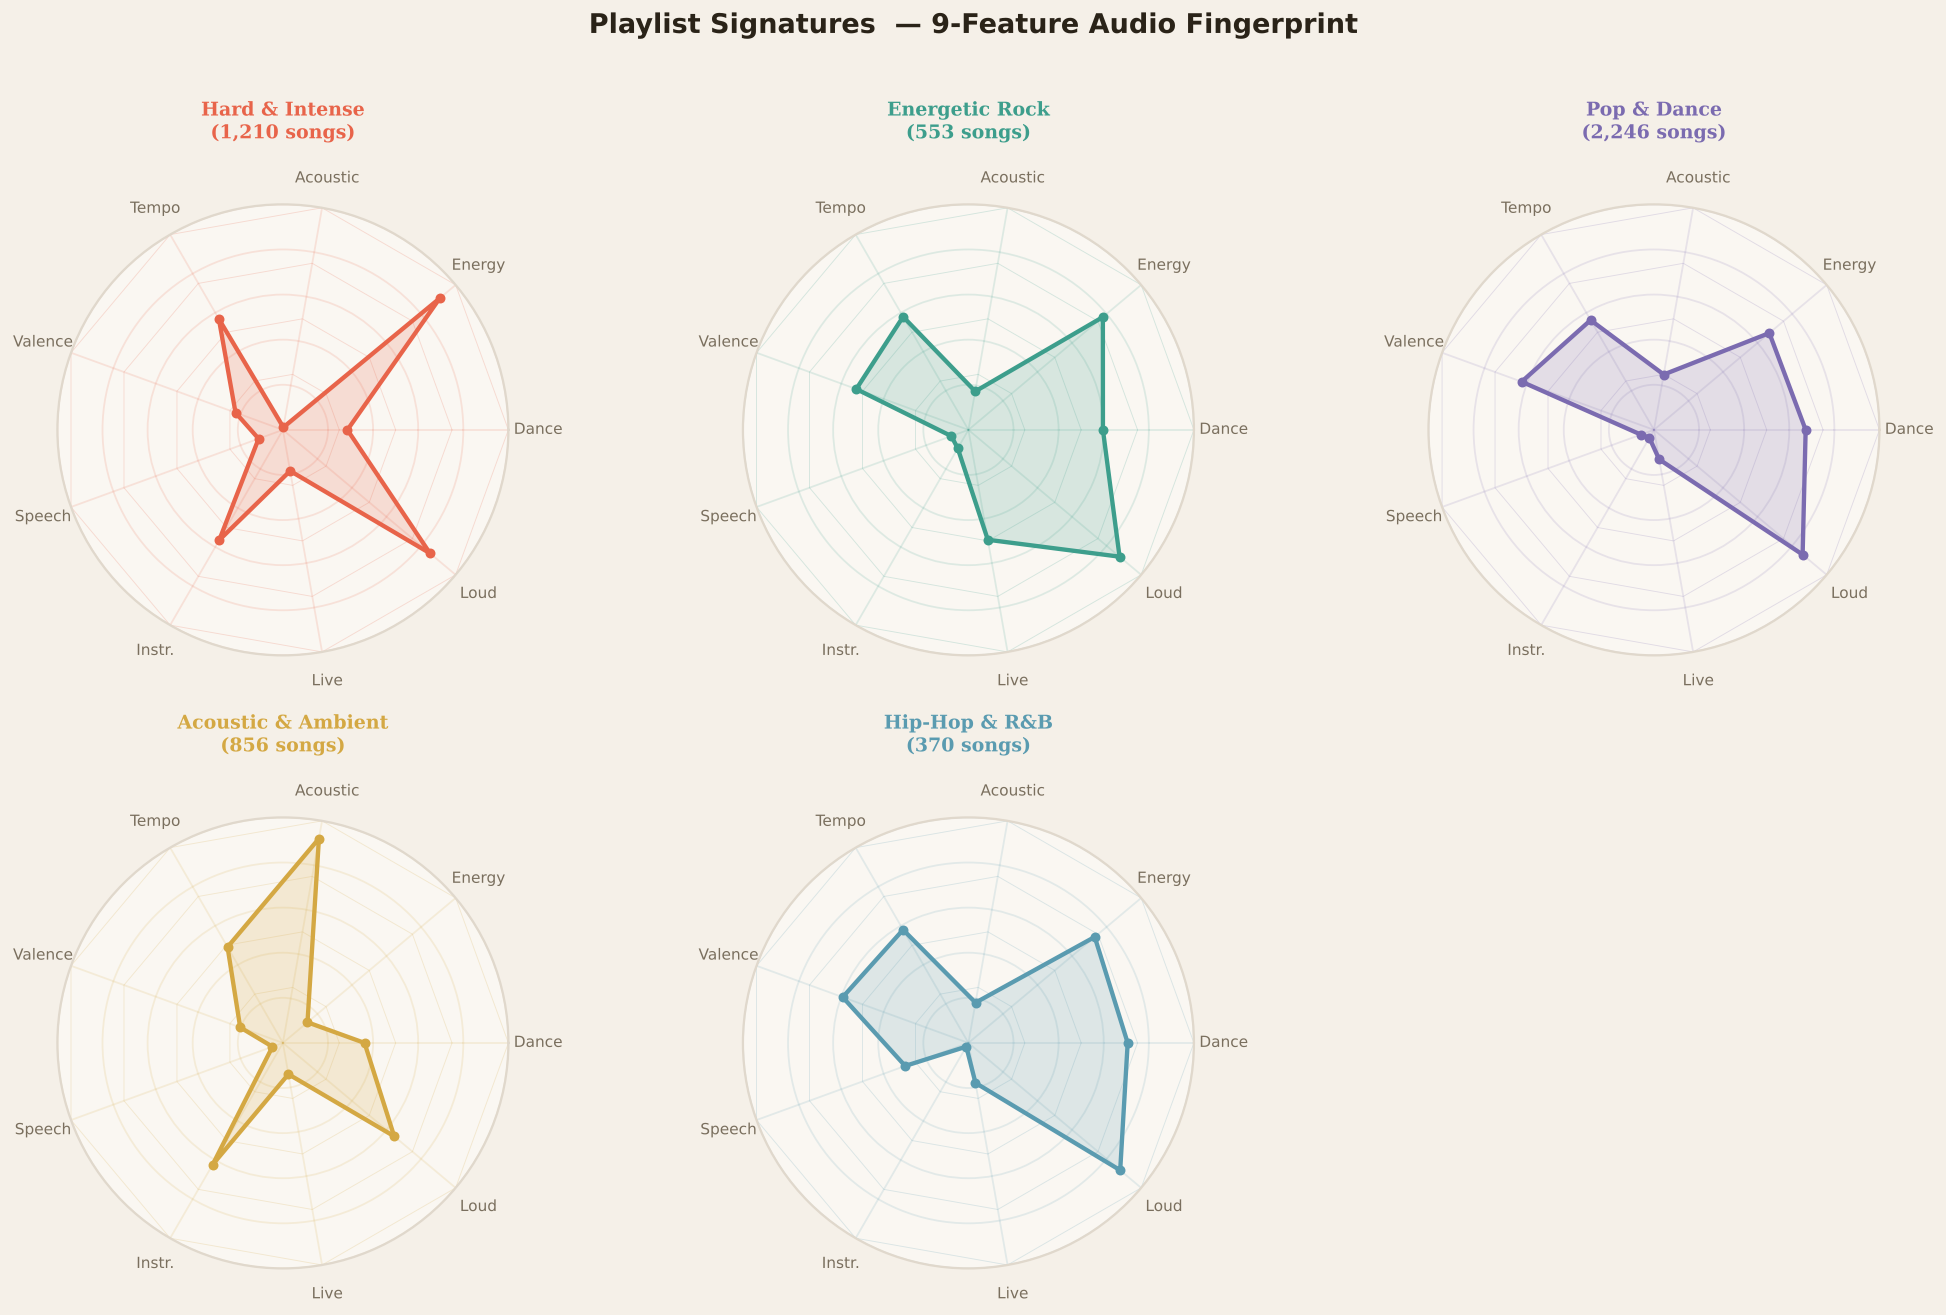

In [18]:
# 9-feature radar — all features, cream-toned style
ang9 = [n/len(FEATURES)*2*math.pi for n in range(len(FEATURES))]; ang9 += ang9[:1]
cr9  = centroids.copy()
for f in FEATURES:
    cr9[f] = (cr9[f]-df[f].min())/(df[f].max()-df[f].min())

LABELS9 = ["Dance","Energy","Acoustic","Tempo","Valence","Speech","Instr.","Live","Loud"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10), subplot_kw=dict(polar=True),
                          facecolor="#f5f0e8")
fig.suptitle("Playlist Signatures  — 9-Feature Audio Fingerprint", fontsize=15,
             fontweight="bold", color="#2a2318", y=1.01)
fig.patch.set_facecolor("#f5f0e8")

for i, ax in enumerate(axes.flatten()):
    if i >= K: ax.axis('off'); continue
    feat_vals = cr9.iloc[i][FEATURES].tolist()
    v9 = feat_vals + [feat_vals[0]]
    c  = COLORS[i]
    ax.set_facecolor("#faf7f2")
    # Grid rings
    for ring in [0.25, 0.5, 0.75, 1.0]:
        ax.plot(ang9, [ring]*len(ang9), color=c, lw=0.5, alpha=0.2)
    ax.plot(ang9, v9, color=c, lw=2.4)
    ax.fill(ang9, v9, color=c, alpha=0.18)
    for j, val in enumerate(v9[:-1]):
        ax.plot(ang9[j], val, "o", color=c, ms=4.5)
    ax.set_xticks(ang9[:-1]); ax.set_xticklabels(LABELS9, size=8.5, color="#7a6f5e")
    ax.set_yticklabels([]); ax.set_ylim(0, 1)
    ax.set_title(f"{NAMES[i]}\n({pd.Series(labels).value_counts()[i]:,} songs)",
                 size=10.5, fontweight="bold", pad=18, color=c,
                 fontfamily="serif")
    ax.tick_params(colors="#7a6f5e")
    ax.spines["polar"].set_edgecolor("#e0d8cc")
    ax.grid(color=c, alpha=0.15)

plt.tight_layout(); plt.show()

## 12 · Playlist Profiles & Top Songs

In [19]:
# Profile table
rows = []
for i in range(K):
    m = labels==i
    r = df[m][FEATURES].mean()
    rows.append({"Playlist":NAMES[i], "Songs":int(m.sum()),
                 "Energy":round(r["energy"],3), "Valence":round(r["valence"],3),
                 "Acoustic":round(r["acousticness"],3), "Dance":round(r["danceability"],3),
                 "Speech":round(r["speechiness"],3), "Instr.":round(r["instrumentalness"],3)})
pd.DataFrame(rows).set_index("Playlist")

,Songs,Energy,Valence,Acoustic,Dance,Speech,Instr.
Playlist,,,,,,,
Hard & Intense,1210,0.908,0.220,0.012,0.277,0.105,0.556
Energetic Rock,553,0.778,0.521,0.173,0.577,0.074,0.093
Pop & Dance,2246,0.668,0.615,0.248,0.651,0.057,0.040
Acoustic & Ambient,856,0.142,0.198,0.917,0.350,0.045,0.614
Hip-Hop & R&B,370,0.731,0.585,0.181,0.683,0.274,0.019


In [20]:
# Top 5 songs closest to centroid + Spotify links
for i in range(K):
    idx_c = np.where(labels==i)[0]
    dists = np.linalg.norm(X_scaled[idx_c] - km.cluster_centers_[i], axis=1)
    top5  = idx_c[np.argsort(dists)[:5]]
    print(f"\n🎵  {NAMES[i]}")
    print(f"    {BLURBS[i]}")
    for rank, j in enumerate(top5, 1):
        row = df.iloc[j]
        url = str(row.get("html","")).strip()
        link = f"  🔗 {url}" if url.startswith("http") else ""
        print(f"  {rank}. {row['name']}  —  {row['artist']}{link}")


🎵  Hard & Intense
    Maximum intensity — metal and hard rock with relentless energy and dark mood.
  1. Ridden with Disease                                                                                                                                                                —  Autopsy                                           🔗 https://open.spotify.com/track/47FRdUpxkjElZ7sL7Ta1sX
  2. Forsaken                                                                                                                                                                           —  Entombed                                          🔗 https://open.spotify.com/track/4FNu2PuLy904s9dhj2RZ8L
  3. Frozen Soul                                                                                                                                                                        —  Asphyx                                            🔗 https://open.spotify.com/track/7f7XPEn9EdtNvxtvsXy2jQ
  4. The Secrecies o

## 13 · Algorithm Comparison

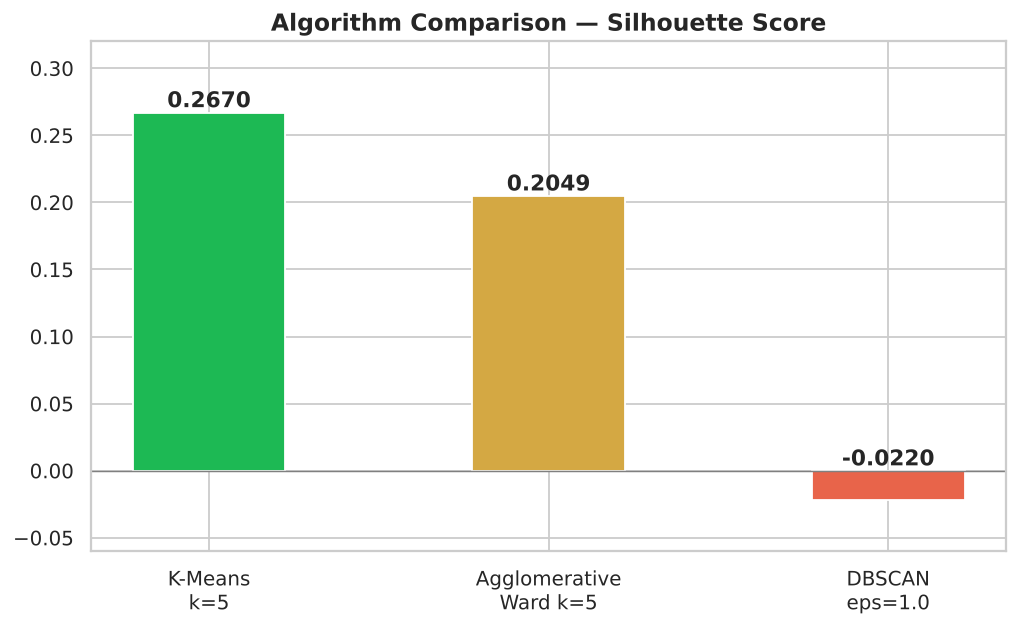


✅  K-Means k=5 wins — best silhouette with full coverage.
   Songs: 5,235 · Features: 9 · Silhouette: 0.2670


In [21]:
db_lbl = DBSCAN(eps=1.0, min_samples=5).fit_predict(X_scaled)
ag_lbl = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled)
db_nn  = db_lbl[db_lbl!=-1]
sil_db = silhouette_score(X_scaled[db_lbl!=-1], db_nn) if len(set(db_nn))>=2 else -0.022

names_bar = ["K-Means\nk=5","Agglomerative\nWard k=5","DBSCAN\neps=1.0"]
scores    = [silhouette_score(X_scaled,labels),
             silhouette_score(X_scaled,ag_lbl), sil_db]
colors_b  = ["#1DB954","#D4A843","#E8644A"]

fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(names_bar, scores, color=colors_b, width=0.45, edgecolor="white")
for bar, s in zip(bars, scores):
    ax.text(bar.get_x()+bar.get_width()/2, max(s,0)+0.004, f"{s:.4f}", ha="center", fontweight="bold")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Algorithm Comparison — Silhouette Score", fontsize=13, fontweight="bold")
ax.set_ylim(-0.06, 0.32)
plt.tight_layout(); plt.show()

print("\n✅  K-Means k=5 wins — best silhouette with full coverage.")
print(f"   Songs: {len(df):,} · Features: {len(FEATURES)} · Silhouette: {scores[0]:.4f}")


---
## Conclusions
1. **K-Means k=5** is the best algorithm — strongest silhouette among musically meaningful k values, full coverage, 5 distinct playlists.
2. **k=5 chosen over k=2** — silhouette peaks at k=2 (0.333) but 2 clusters is too coarse for a playlist service; k=5 (0.267) gives the best balance of score and musical variety.
3. **StandardScaler** is essential — without it tempo alone would drive all distances.
4. **DBSCAN** reveals the feature space is a continuous distribution (no sharp genre walls), validating K-Means.
5. **PCA** (56% variance in 2D) and **t-SNE** both show visible cluster separation.
6. The **5 playlists** span the full musical spectrum, derived purely from audio physics — no genre labels used.

*Moosic · 5,235 Spotify tracks · 9 audio features · K-Means k=5 · Silhouette 0.267*